first 5 rows:
                 track_id                 artists  \
0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   
3  Can't Help Falling In Love          71       201933    

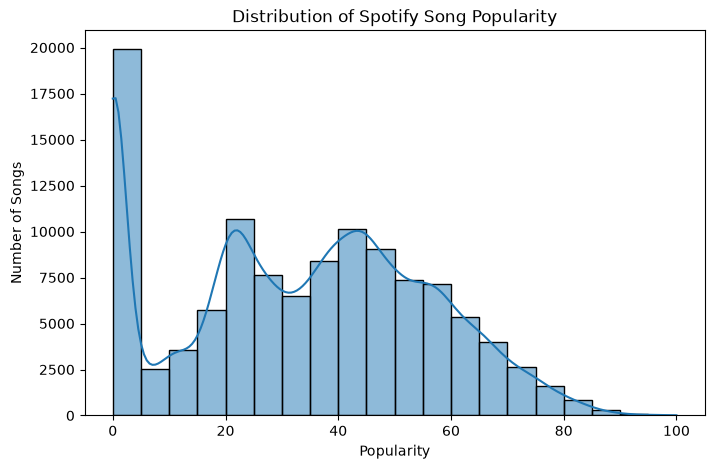

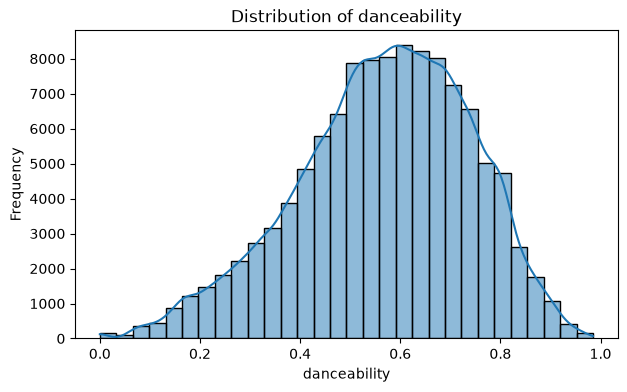

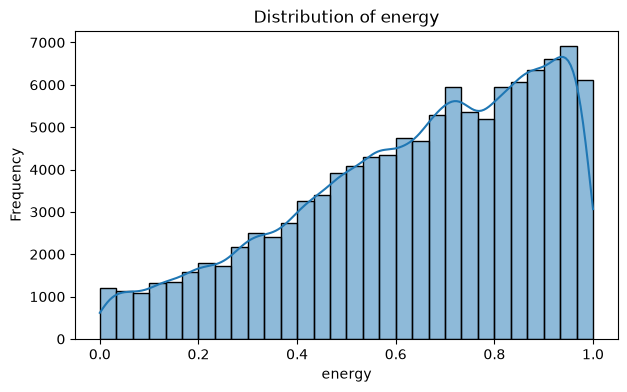

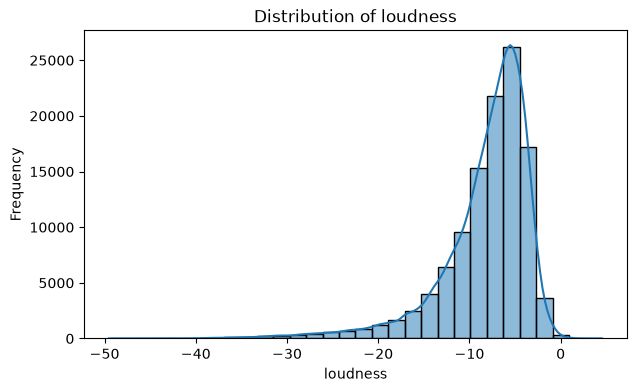

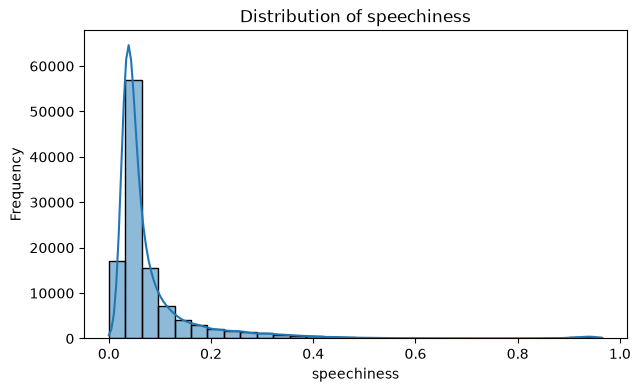

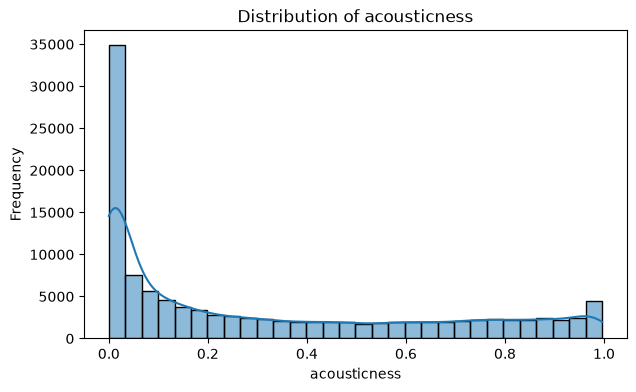

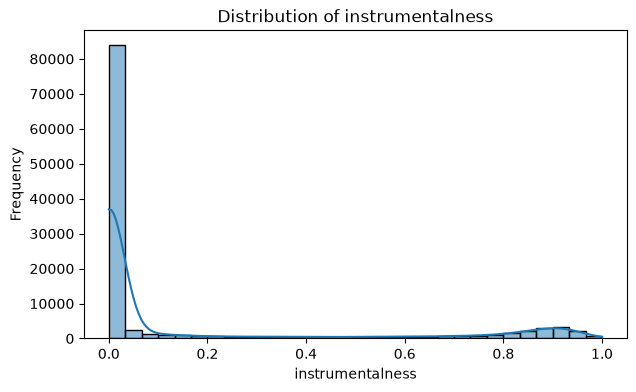

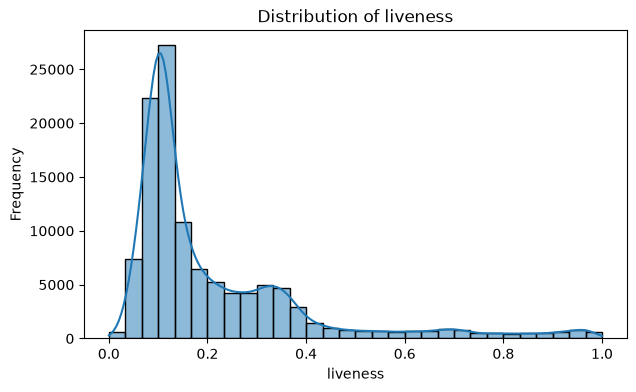

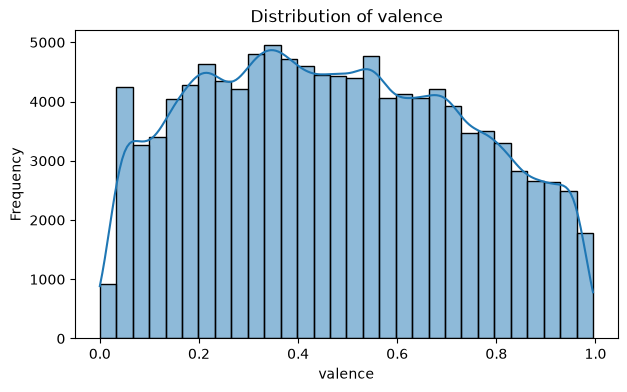

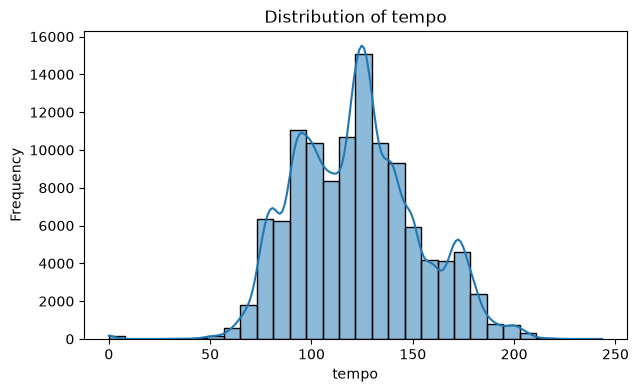

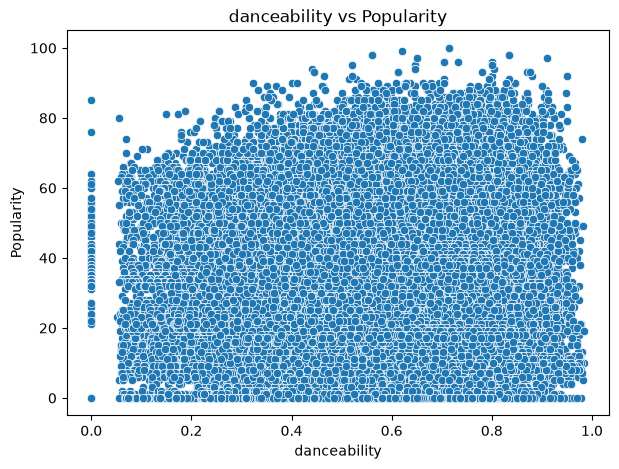

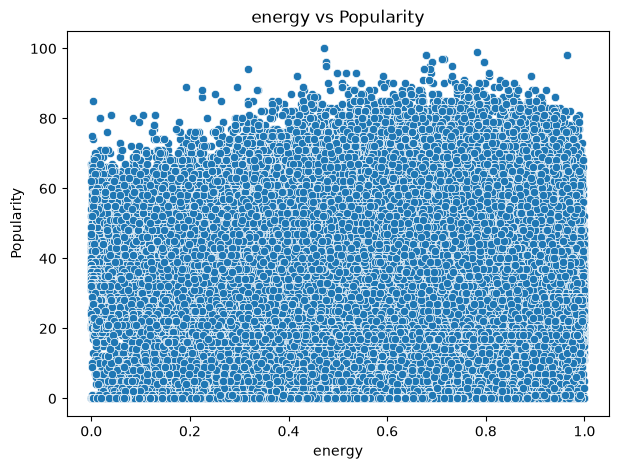

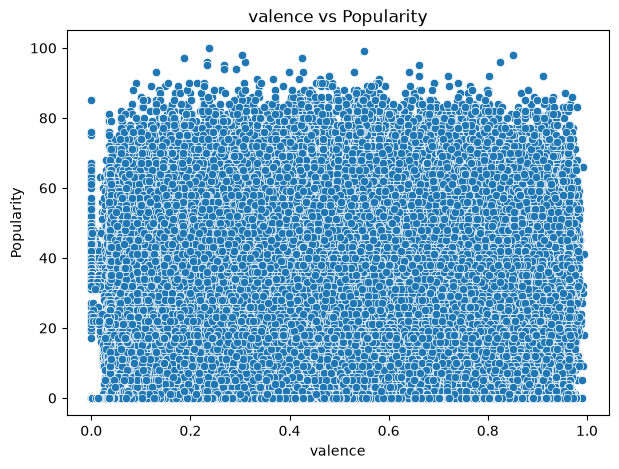

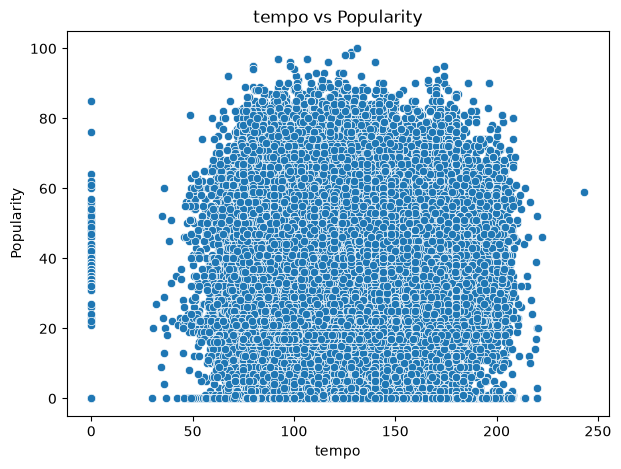

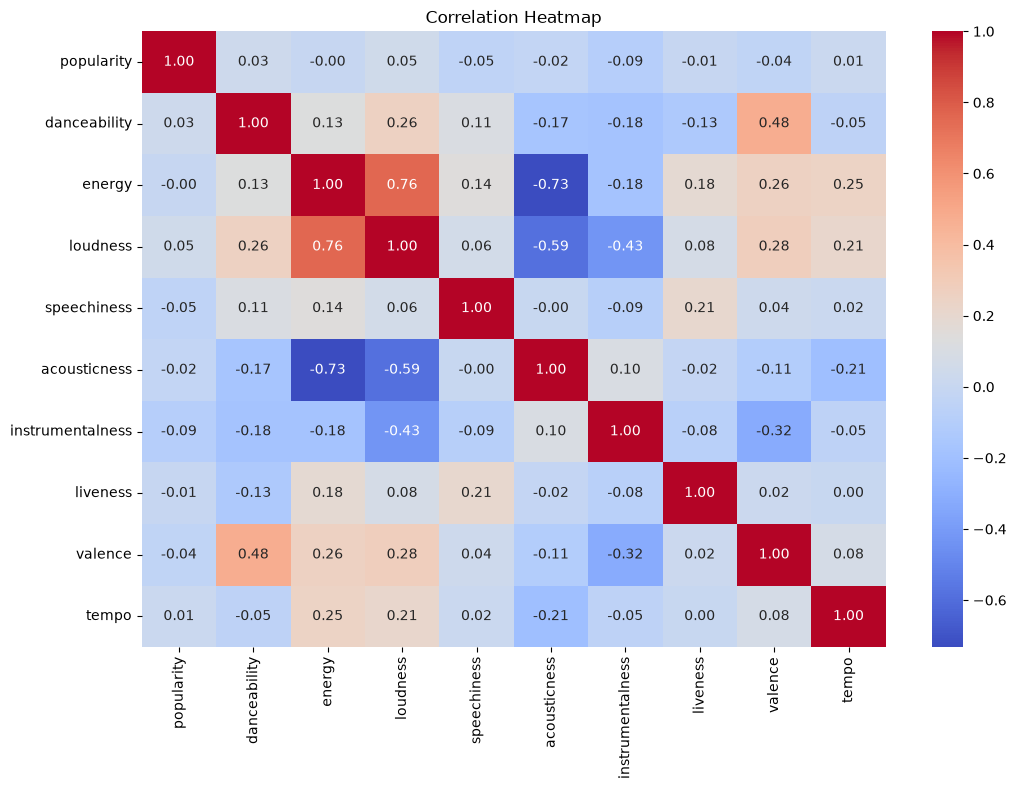

Popularity Category Counts:
popularity_category
Not Popular           65000
Moderately Popular    43081
Popular                5468
Name: count, dtype: int64


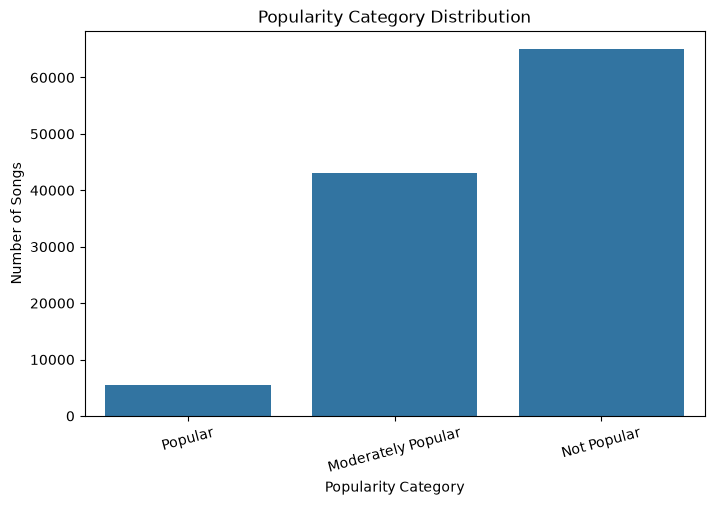

Selected Features:
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Shape of X: (113549, 9)
Shape of y: (113549,)
Training Data Shape: (90839, 9)
Testing Data Shape: (22710, 9)
Feature Scaling Completed

LOGISTIC REGRESSION
                    precision    recall  f1-score   support

Moderately Popular       0.52      0.19      0.28      8616
       Not Popular       0.60      0.90      0.72     13000
           Popular       0.00      0.00      0.00      1094

          accuracy                           0.59     22710
         macro avg       0.37      0.36      0.33     22710
      weighted avg       0.54      0.59      0.52     22710


DECISION TREE
                    precision    recall  f1-score   support

Moderately Popular       0.64      0.66      0.65      8616
       Not Popular       0.77      0.74      0.76     13000
           Popular       0.50      0.61      0.55      1094

          accuracy     

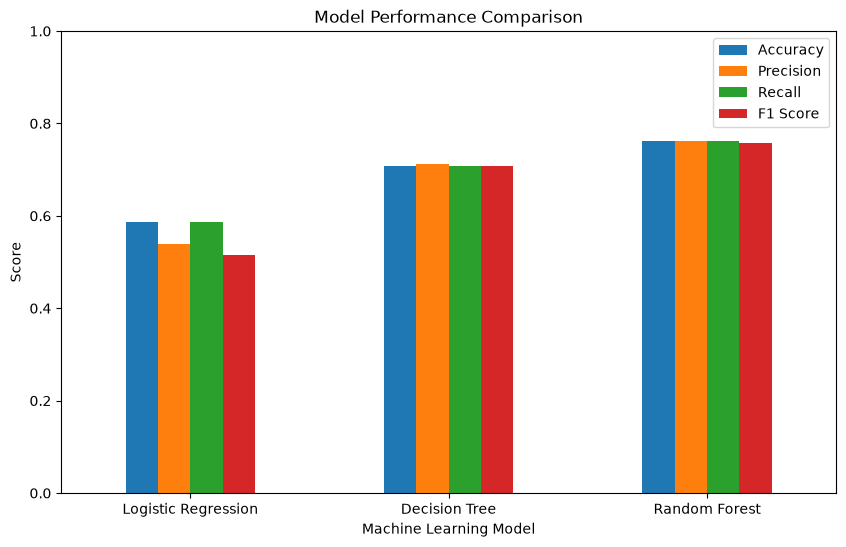

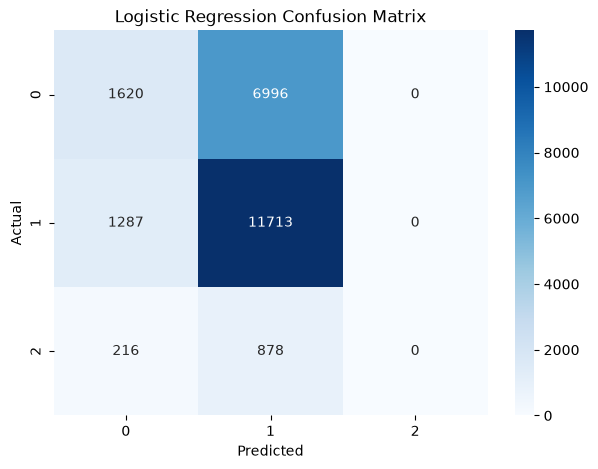

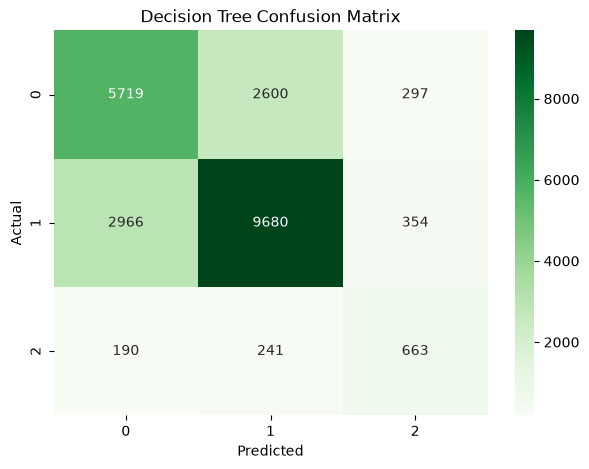

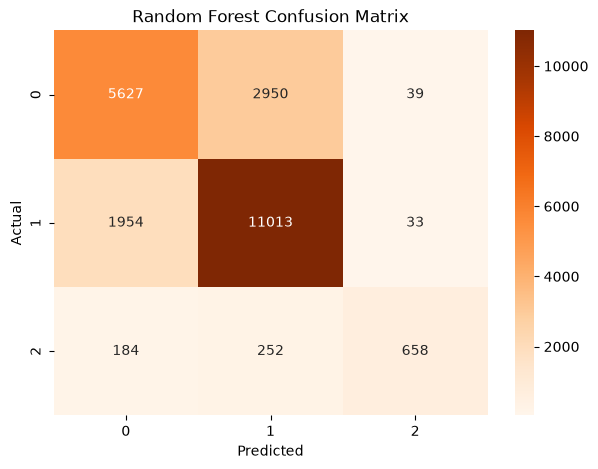


RANDOM FOREST FEATURE IMPORTANCE
            Feature  Importance
4      acousticness    0.119288
7           valence    0.116997
8             tempo    0.116382
2          loudness    0.115721
0      danceability    0.114540
3       speechiness    0.113884
1            energy    0.112626
6          liveness    0.109593
5  instrumentalness    0.080968


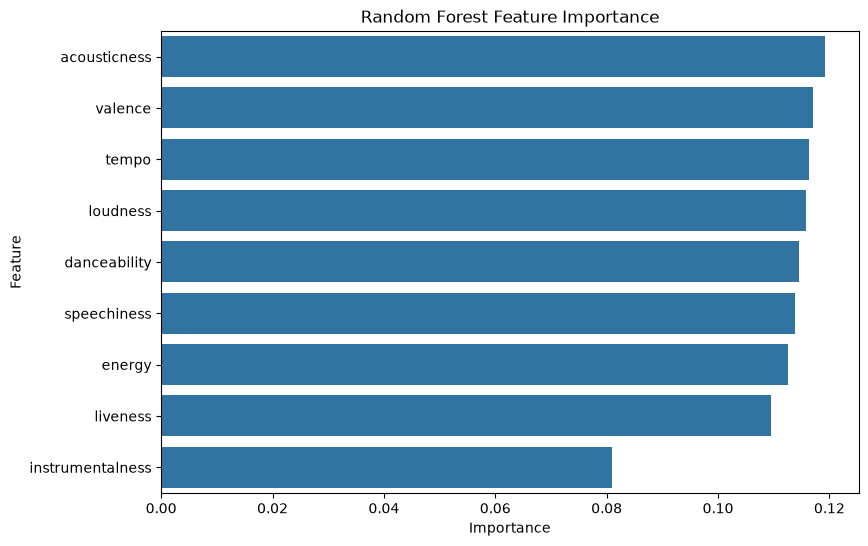


NEW SONG PREDICTION
Predicted Popularity Category: Not Popular
Random Forest Prediction: Not Popular

Successfull


In [1]:
# SPOTIFY SONG POPULARITY PREDICTION


# IMPORT LIBRARIES


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



# LOAD DATASET


df = pd.read_csv("spotify-tracks-dataset-detailed (1).csv")



# UNDERSTANDING THE DATASET


print("first 5 rows:")
print(df.head())

# print(df.tail())

print("Shape Of The Dataset:", df.shape)

print("Number Of Rows:", df.shape[0])

print("Columns:", df.columns)

print("Information:")
print(df.info())

print("Description:")
print(df.describe(include="all"))



# MISSING VALUES


df_drop = df.dropna()

print("Shape after removing the missing values:", df_drop.shape)

print("Missing Values After Dropna():")
print(df_drop.isnull().sum())

missing_index = df[df['popularity'].isnull()].index

print("Index of rows with missing 'popularity' values:", missing_index)

original_values = df.loc[missing_index, 'popularity'].copy()


# calculate mean
mean_value = df["popularity"].mean()

print("Mean Value of 'popularity':", mean_value)


# fill missing values with mean
df["popularity"] = df["popularity"].fillna(mean_value)



# DUPLICATE ROWS


df_duplicated = df[df.duplicated()]

print("Number of Duplicate Rows:", df_duplicated.shape[0])


# remove duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicate rows:", df.shape)



# UNNECESSARY COLUMNS


df_unnecessary = df.drop(['Unnamed: 0'], axis=1, errors='ignore')

print("Shape after removing unnecessary columns:", df_unnecessary.shape)

print("Columns after removing unnecessary columns:")
print(df_unnecessary.columns)


# REMOVE REMAINING MISSING VALUES


df = df_unnecessary.dropna().copy()

print("Final Shape after cleaning:", df.shape)

print("Missing values after cleaning:")
print(df.isnull().sum())


# EXPLORATORY DATA ANALYSIS


# POPULARITY DISTRIBUTION


plt.figure(figsize=(8, 5))

sns.histplot(
    df["popularity"],
    bins=20,
    kde=True
)

plt.title("Distribution of Spotify Song Popularity")

plt.xlabel("Popularity")

plt.ylabel("Number of Songs")

plt.show()

# FEATURE DISTRIBUTION


features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

for feature in features:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        df[feature],
        bins=30,
        kde=True
    )

    plt.title("Distribution of " + feature)

    plt.xlabel(feature)

    plt.ylabel("Frequency")

    plt.show()


# SCATTER PLOTS


scatter_features = [
    "danceability",
    "energy",
    "valence",
    "tempo"
]

for feature in scatter_features:

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        x=df[feature],
        y=df["popularity"]
    )

    plt.title(feature + " vs Popularity")

    plt.xlabel(feature)

    plt.ylabel("Popularity")

    plt.show()

# CORRELATION HEATMAP


correlation_columns = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


# CREATE TARGET CLASSES


def popularity_category(popularity):

    if popularity >= 70:
        return "Popular"

    elif popularity >= 40:
        return "Moderately Popular"

    else:
        return "Not Popular"


df["popularity_category"] = df["popularity"].apply(
    popularity_category
)


print("Popularity Category Counts:")

print(
    df["popularity_category"].value_counts()
)

# TARGET CLASS DISTRIBUTION


plt.figure(figsize=(8, 5))

sns.countplot(
    x=df["popularity_category"]
)

plt.title("Popularity Category Distribution")

plt.xlabel("Popularity Category")

plt.ylabel("Number of Songs")

plt.xticks(rotation=15)

plt.show()



# FEATURE SELECTION


features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X = df[features]

y = df["popularity_category"]


print("Selected Features:")

print(features)

print("Shape of X:", X.shape)

print("Shape of y:", y.shape)


# TRAIN TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)



# FEATURE SCALING


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


print("Feature Scaling Completed")


# LOGISTIC REGRESSION


logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_prediction = logistic_model.predict(
    X_test_scaled
)


print("\nLOGISTIC REGRESSION")

print(
    classification_report(
        y_test,
        logistic_prediction
    )
)


# DECISION TREE


decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_prediction = decision_tree_model.predict(
    X_test
)


print("\nDECISION TREE")

print(
    classification_report(
        y_test,
        decision_tree_prediction
    )
)


# RANDOM FOREST


random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_prediction = random_forest_model.predict(
    X_test
)


print("\nRANDOM FOREST")

print(
    classification_report(
        y_test,
        random_forest_prediction
    )
)


# MODEL EVALUATION

# Logistic Regression

logistic_accuracy = accuracy_score(
    y_test,
    logistic_prediction
)

logistic_precision = precision_score(
    y_test,
    logistic_prediction,
    average="weighted"
)

logistic_recall = recall_score(
    y_test,
    logistic_prediction,
    average="weighted"
)

logistic_f1 = f1_score(
    y_test,
    logistic_prediction,
    average="weighted"
)


# Decision Tree

tree_accuracy = accuracy_score(
    y_test,
    decision_tree_prediction
)

tree_precision = precision_score(
    y_test,
    decision_tree_prediction,
    average="weighted"
)

tree_recall = recall_score(
    y_test,
    decision_tree_prediction,
    average="weighted"
)

tree_f1 = f1_score(
    y_test,
    decision_tree_prediction,
    average="weighted"
)


# Random Forest

forest_accuracy = accuracy_score(
    y_test,
    random_forest_prediction
)

forest_precision = precision_score(
    y_test,
    random_forest_prediction,
    average="weighted"
)

forest_recall = recall_score(
    y_test,
    random_forest_prediction,
    average="weighted"
)

forest_f1 = f1_score(
    y_test,
    random_forest_prediction,
    average="weighted"
)


# MODEL COMPARISON

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ],

    "Precision": [
        logistic_precision,
        tree_precision,
        forest_precision
    ],

    "Recall": [
        logistic_recall,
        tree_recall,
        forest_recall
    ],

    "F1 Score": [
        logistic_f1,
        tree_f1,
        forest_f1
    ]

})


print("\nMODEL COMPARISON")

print(model_comparison)


# MODEL COMPARISON GRAPH

model_comparison_plot = model_comparison.set_index(
    "Model"
)

model_comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")

plt.xlabel("Machine Learning Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend()

plt.show()


# CONFUSION MATRIX - LOGISTIC REGRESSION

logistic_cm = confusion_matrix(
    y_test,
    logistic_prediction
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


# CONFUSION MATRIX - DECISION TREE

tree_cm = confusion_matrix(
    y_test,
    decision_tree_prediction
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


# CONFUSION MATRIX - RANDOM FOREST

forest_cm = confusion_matrix(
    y_test,
    random_forest_prediction
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    forest_cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


# RANDOM FOREST FEATURE IMPORTANCE

feature_importance = pd.DataFrame({

    "Feature": features,

    "Importance":
        random_forest_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


print("\nRANDOM FOREST FEATURE IMPORTANCE")

print(feature_importance)


# FEATURE IMPORTANCE GRAPH

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.show()


# NEW SONG PREDICTION

new_song = pd.DataFrame({

    "danceability": [0.80],

    "energy": [0.75],

    "loudness": [-5.0],

    "speechiness": [0.05],

    "acousticness": [0.10],

    "instrumentalness": [0.00],

    "liveness": [0.10],

    "valence": [0.80],

    "tempo": [120.0]

})


# Scale new song using the same scaler

new_song_scaled = scaler.transform(
    new_song
)


# Predict using Logistic Regression

new_song_prediction = logistic_model.predict(
    new_song_scaled
)


print("\nNEW SONG PREDICTION")

print(
    "Predicted Popularity Category:",
    new_song_prediction[0]
)


# NEW SONG PREDICTION USING RANDOM FOREST

new_song_rf_prediction = random_forest_model.predict(
    new_song
)


print(
    "Random Forest Prediction:",
    new_song_rf_prediction[0]
)


print("\nSuccessfull")